In [ ]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score, accuracy_score,
                             precision_score, recall_score, f1_score, confusion_matrix)

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)

SEMILLA = 42

def fijar_semilla(semilla):
    # Fija las semillas de Python, NumPy y TensorFlow a la vez
    keras.utils.set_random_seed(semilla)

fijar_semilla(SEMILLA)
tf.config.experimental.enable_op_determinism()
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


In [ ]:
RUTA_CSV = 'DatasetCreditoFinancieroFinalV2.csv'

if not os.path.exists(RUTA_CSV):
    try:
        from google.colab import files
        print(f'Sube el archivo {RUTA_CSV}')
        subidos = files.upload()
        RUTA_CSV = next(iter(subidos))
    except ImportError:
        raise FileNotFoundError(f'No se encontró {RUTA_CSV}; ajusta RUTA_CSV.')

df = pd.read_csv(RUTA_CSV, encoding='utf-8-sig')   # UTF-8 con BOM, según el diccionario
print('Dimensiones:', df.shape)
df.head()

Dimensiones: (49650, 26)


,id_solicitud,edad,ingreso_mensual,obligaciones_mensuales,estado_civil,ingreso_disponible,monto_solicitado,plazo_meses,cuota_estimada,tasa_interes_ea,nivel_endeudamiento_pct,score_crediticio,numero_creditos_activos,saldo_total_creditos,numero_cuotas_mora,dias_maximo_mora,porcentaje_pagos_oportunos,antiguedad_laboral_anios,patrimonio_indice,antiguedad_cliente_anios,linea_negocio,tipo_contrato,personas_a_cargo,tipo_vivienda,APTO_PARA_CREDITO,INCUMPLIO_PAGO
0,172745,43.9,202500.0,153454.09,Single / not married,13522.91,835380.0,48.0,35523.0,49.31,93.32,585.0,2.0,2619045.0,0.0,0.0,100.00,7.17,4,7.74,Cash loans,Working,1,House / apartment,0,1
1,413676,39.1,405000.0,370935.00,Single / not married,9472.50,508495.5,48.0,24592.5,62.88,97.66,325.0,6.0,4129510.5,1.0,1.0,88.89,5.76,2,5.11,Cash loans,Working,1,House / apartment,0,1
2,270588,29.2,157500.0,0.00,Married,144913.50,270000.0,48.0,12586.5,58.78,7.99,265.0,NaN,NaN,9.0,51.0,57.14,3.47,1,3.03,Cash loans,Commercial associate,1,House / apartment,0,1
3,183124,58.2,90000.0,39606.71,Married,36893.29,270000.0,48.0,13500.0,66.75,59.01,527.0,1.0,NaN,3.0,2.0,90.62,5.20,1,2.85,Revolving loans,Working,0,House / apartment,0,1
4,165787,38.9,90000.0,2076.29,Single / not married,66017.71,675000.0,60.0,21906.0,34.70,26.65,183.0,NaN,NaN,0.0,0.0,100.00,2.28,2,1.28,Cash loans,Working,0,House / apartment,0,1


In [ ]:
assert df.shape == (49650, 26), 'El archivo no tiene las dimensiones del diccionario'
assert df['id_solicitud'].is_unique
assert ((df['APTO_PARA_CREDITO'] + df['INCUMPLIO_PAGO']) == 1).all(), 'INCUMPLIO_PAGO no es el complemento'

print('Balance de clases:', df['APTO_PARA_CREDITO'].value_counts().to_dict())
print('Filas con al menos un vacío: {:.1%}'.format(df.isna().any(axis=1).mean()))
(df.isna().mean() * 100).round(2).loc[lambda s: s > 0].sort_values(ascending=False).to_frame('% vacíos')

Balance de clases: {0: 24825, 1: 24825}
Filas con al menos un vacío: 44.9%


,% vacíos
saldo_total_creditos,32.35
numero_creditos_activos,16.03
antiguedad_laboral_anios,15.28
antiguedad_cliente_anios,4.66
porcentaje_pagos_oportunos,4.53
obligaciones_mensuales,3.84
numero_cuotas_mora,3.60
dias_maximo_mora,0.70
score_crediticio,0.06
plazo_meses,0.02


In [ ]:
OBJETIVO = 'APTO_PARA_CREDITO'
EXCLUIDAS = ['id_solicitud', 'INCUMPLIO_PAGO']

# La primera categoría de cada lista es la de referencia (k-1)
CATEGORIAS = {
    'estado_civil':  ['Married', 'Single / not married', 'Civil marriage', 'Separated', 'Widow'],
    'linea_negocio': ['Cash loans', 'Revolving loans'],
    'tipo_contrato': ['Working', 'Commercial associate', 'Pensioner', 'State servant',
                      'Unemployed', 'Maternity leave', 'Student', 'Businessman'],
    'tipo_vivienda': ['House / apartment', 'With parents', 'Municipal apartment',
                      'Rented apartment', 'Office apartment', 'Co-op apartment'],
}
NUMERICAS = [c for c in df.columns if c not in EXCLUIDAS + [OBJETIVO] + list(CATEGORIAS)]
TODAS = NUMERICAS + list(CATEGORIAS)          # las 23 variables predictoras

# Variables con cola larga (montos, razones y conteos): candidatas a transformación logarítmica
COLA_LARGA = ['ingreso_mensual', 'obligaciones_mensuales', 'ingreso_disponible', 'monto_solicitado',
              'cuota_estimada', 'nivel_endeudamiento_pct', 'saldo_total_creditos',
              'numero_creditos_activos', 'numero_cuotas_mora', 'dias_maximo_mora', 'personas_a_cargo']

for var, cats in CATEGORIAS.items():
    sobrantes = set(df[var].unique()) - set(cats)
    assert not sobrantes, f'{var} tiene categorías no previstas: {sobrantes}'

n_dummies = sum(len(c) - 1 for c in CATEGORIAS.values())
print(f'Numéricas: {len(NUMERICAS)} | Dummies: {n_dummies} | Entradas sin indicadores: {len(NUMERICAS) + n_dummies}')

Numéricas: 19 | Dummies: 17 | Entradas sin indicadores: 36


In [ ]:
X = df.drop(columns=EXCLUIDAS + [OBJETIVO])
y = df[OBJETIVO].values

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=SEMILLA)

pd.DataFrame({
    'Registros': [len(X_train), len(X_val), len(X_test)],
    '% del total': [len(X_train)/len(X), len(X_val)/len(X), len(X_test)/len(X)],
    '% aptos': [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=['Entrenamiento', 'Validación', 'Prueba']).round(3)

,Registros,% del total,% aptos
Entrenamiento,34755,0.7,0.5
Validación,4965,0.1,0.5
Prueba,9930,0.2,0.5


In [ ]:
class Preprocesador:
    def __init__(self, imputacion='mediana', indicadores=False, transformacion='estandar', variables=None):
        assert imputacion in ('mediana', 'cero')
        assert transformacion in ('estandar', 'log', 'recorte')
        self.imputacion, self.indicadores, self.transformacion = imputacion, indicadores, transformacion
        variables = TODAS if variables is None else variables
        self.numericas = [c for c in NUMERICAS if c in variables]
        self.categorias = {v: cats for v, cats in CATEGORIAS.items() if v in variables}
        self.cola_larga = [c for c in COLA_LARGA if c in self.numericas]

    def _transformar(self, Xn, ajustar):
        if self.transformacion == 'log':
            Xn[self.cola_larga] = np.sign(Xn[self.cola_larga]) * np.log1p(Xn[self.cola_larga].abs())
        elif self.transformacion == 'recorte':
            if ajustar:
                self.p01, self.p99 = Xn.quantile(0.01), Xn.quantile(0.99)
            Xn = Xn.clip(self.p01, self.p99, axis=1)
        return Xn

    def fit(self, X):
        Xn = X[self.numericas].astype(float).copy()
        self.cols_indicador = [c for c in self.numericas if Xn[c].isna().mean() > 0.01] if self.indicadores else []
        Xn = self._transformar(Xn, ajustar=True)
        self.relleno = Xn.median() if self.imputacion == 'mediana' else pd.Series(0.0, index=self.numericas)
        Xn = Xn.fillna(self.relleno)
        self.media, self.desv = Xn.mean(), Xn.std(ddof=0).replace(0, 1)
        self.nombres = (self.numericas + ['falta_' + c for c in self.cols_indicador] +
                        [f'{v}={c}' for v, cats in self.categorias.items() for c in cats[1:]])
        return self

    def transform(self, X):
        Xn = X[self.numericas].astype(float).copy()
        indic = Xn[self.cols_indicador].isna().astype(float).values
        Xn = self._transformar(Xn, ajustar=False).fillna(self.relleno)
        Xn = ((Xn - self.media) / self.desv).values
        partes = [Xn, indic]
        if self.categorias:
            partes.append(np.column_stack([(X[v].values == c).astype(float)
                                           for v, cats in self.categorias.items() for c in cats[1:]]))
        return np.hstack(partes).astype('float32')

    def a_diccionario(self):
        # Todos los valores aprendidos en el entrenamiento, en un formato que se puede guardar como JSON
        d = dict(imputacion=self.imputacion, indicadores=self.indicadores, transformacion=self.transformacion,
                 numericas=self.numericas, categorias=self.categorias, cola_larga=self.cola_larga,
                 cols_indicador=self.cols_indicador, nombres_entradas=self.nombres,
                 relleno={k: float(v) for k, v in self.relleno.items()},
                 media={k: float(v) for k, v in self.media.items()},
                 desv={k: float(v) for k, v in self.desv.items()})
        if self.transformacion == 'recorte':
            d['p01'] = {k: float(v) for k, v in self.p01.items()}
            d['p99'] = {k: float(v) for k, v in self.p99.items()}
        return d

# Prueba rápida
_p = Preprocesador(indicadores=True).fit(X_train)
print('Entradas con indicadores:', _p.transform(X_val).shape[1])
print('Columnas con indicador de vacío:', _p.cols_indicador)

Entradas con indicadores: 43
Columnas con indicador de vacío: ['obligaciones_mensuales', 'numero_creditos_activos', 'saldo_total_creditos', 'numero_cuotas_mora', 'porcentaje_pagos_oportunos', 'antiguedad_laboral_anios', 'antiguedad_cliente_anios']


In [ ]:
def construir_red(n_entradas, dropout=0.2, activacion='relu', tasa_aprendizaje=0.001):
    assert activacion in ('relu', 'leaky_relu')
    modelo = keras.Sequential([
        keras.Input(shape=(n_entradas,)),
        layers.Dense(64, activation=activacion, kernel_initializer='he_normal', bias_initializer='zeros', name='oculta_1'),
        layers.Dropout(dropout),
        layers.Dense(32, activation=activacion, kernel_initializer='he_normal', bias_initializer='zeros', name='oculta_2'),
        layers.Dropout(dropout),
        layers.Dense(16, activation=activacion, kernel_initializer='he_normal', bias_initializer='zeros', name='oculta_3'),
        layers.Dropout(dropout),
        layers.Dense(1, activation='sigmoid', kernel_initializer='glorot_uniform', bias_initializer='zeros', name='salida'),
    ])
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=tasa_aprendizaje),
                   loss='binary_crossentropy',
                   metrics=[keras.metrics.AUC(name='auc'), 'accuracy'])
    return modelo


def entrenar(modelo, Xtr, ytr, Xva, yva, tam_lote, verbose=0, max_epocas=200):
    callbacks = [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=5, min_lr=1e-4),
    ]
    return modelo.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=max_epocas, batch_size=tam_lote,
                      callbacks=callbacks, verbose=verbose, shuffle=True)


def neuronas_muertas(modelo, X):
    # % de neuronas de cada capa oculta cuya salida ReLU es 0 para todos los registros de X
    pesos = modelo.get_weights()          # [W1, b1, W2, b2, W3, b3, W_salida, b_salida]
    a, resultado = X, []
    for capa in range(3):
        a = np.maximum(a @ pesos[2 * capa] + pesos[2 * capa + 1], 0)
        resultado.append(100 * float((a.max(axis=0) <= 0).mean()))
    return resultado


def correr_configuracion(imputacion, indicadores, transformacion, dropout, tam_lote,
                         activacion='relu', variables=None, semilla=SEMILLA):
    # Entrena una configuración completa y devuelve sus métricas de validación
    fijar_semilla(semilla)
    prep = Preprocesador(imputacion, indicadores, transformacion, variables).fit(X_train)
    Xtr, Xva = prep.transform(X_train), prep.transform(X_val)
    modelo = construir_red(Xtr.shape[1], dropout, activacion)
    inicio = time.time()
    hist = entrenar(modelo, Xtr, y_train, Xva, y_val, tam_lote)
    p_val = modelo.predict(Xva, verbose=0).ravel()
    muertas = sum(neuronas_muertas(modelo, Xva)) / 3 if activacion == 'relu' else np.nan
    return dict(imputacion=imputacion, indicadores=indicadores, transformacion=transformacion,
                dropout=dropout, tam_lote=tam_lote, activacion=activacion, semilla=semilla,
                n_variables=len(variables) if variables is not None else len(TODAS), entradas=Xtr.shape[1],
                epocas=len(hist.history['loss']), auc_val=roc_auc_score(y_val, p_val),
                perdida_val=min(hist.history['val_loss']), neuronas_muertas_pct=muertas,
                segundos=round(time.time() - inicio, 1))

construir_red(43).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 64)             │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_3 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,441 (21.25 KB)

 Trainable params: 5,441 (21.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
EJECUTAR_POOLS = True
SEMILLAS_POOL = [42, 43, 44]

# Se usan si EJECUTAR_POOLS = False. Preprocesamiento, Dropout y lote: corrida del equipo en Colab (23/10/2026).
# Activación: corrida de referencia del pool 3. Si ejecutan los pools, se reemplazan por los resultados nuevos.
CONFIG_ELEGIDA = dict(imputacion='mediana', indicadores=True, transformacion='log',
                      dropout=0.2, tam_lote=32, activacion='relu')

def resumir(resultados, columnas):
    return (resultados.groupby(columnas)
            .agg(auc_val=('auc_val', 'mean'), desv_auc=('auc_val', 'std'), perdida_val=('perdida_val', 'mean'),
                 epocas=('epocas', 'mean'), entradas=('entradas', 'first'))
            .sort_values('auc_val', ascending=False).round(4))

def promedio_ultimas(filas):
    return np.mean([f['auc_val'] for f in filas[-len(SEMILLAS_POOL):]])

In [ ]:
if EJECUTAR_POOLS:
    filas = []
    for imp in ['mediana', 'cero']:
        for ind in [False, True]:
            for tra in ['estandar', 'log', 'recorte']:
                for s in SEMILLAS_POOL:
                    filas.append(correr_configuracion(imp, ind, tra, dropout=0.2, tam_lote=64, semilla=s))
                print(f'{imp:8s} indicadores={str(ind):5s} {tra:9s} AUC val = {promedio_ultimas(filas):.4f}')
    pool1 = pd.DataFrame(filas)
    pool1.to_csv('pool1_preprocesamiento.csv', index=False)
    resumen1 = resumir(pool1, ['imputacion', 'indicadores', 'transformacion'])
    display(resumen1)
    mejor_imp, mejor_ind, mejor_tra = resumen1.index[0]
    CONFIG_ELEGIDA.update(imputacion=mejor_imp, indicadores=bool(mejor_ind), transformacion=mejor_tra)
    print('Comparación directa de la imputación (promedio sobre las demás opciones):')
    display(pool1.groupby('imputacion')['auc_val'].agg(['mean', 'std']).round(4))

mediana  indicadores=False estandar  AUC val = 0.7422
mediana  indicadores=False log       AUC val = 0.7436
mediana  indicadores=False recorte   AUC val = 0.7419
mediana  indicadores=True  estandar  AUC val = 0.7427
mediana  indicadores=True  log       AUC val = 0.7436
mediana  indicadores=True  recorte   AUC val = 0.7421
cero     indicadores=False estandar  AUC val = 0.7421
cero     indicadores=False log       AUC val = 0.7413
cero     indicadores=False recorte   AUC val = 0.7410
cero     indicadores=True  estandar  AUC val = 0.7430
cero     indicadores=True  log       AUC val = 0.7430
cero     indicadores=True  recorte   AUC val = 0.7420


auc_val  desv_auc  perdida_val   epocas  entradas
imputacion indicadores transformacion                                                   
mediana    True        log              0.7436    0.0012       0.5962  24.3333        43
           False       log              0.7436    0.0001       0.5961  27.6667        36
cero       True        log              0.7430    0.0021       0.5965  28.0000        43
                       estandar         0.7430    0.0010       0.5971  28.0000        43
mediana    True        estandar         0.7427    0.0007       0.5969  22.6667        43
           False       estandar         0.7422    0.0009       0.5976  29.0000        36
cero       False       estandar         0.7421    0.0003       0.5981  29.3333        36
mediana    True        recorte          0.7421    0.0014       0.5975  24.6667        43
cero       True        recorte          0.7420    0.0017       0.5980  24.6667        43
mediana    False       recorte          0.7419    0.0010       0.5981  24.3333        36
cero       False       log              0.7413    0.0008       0.5979  33.3333        36
                       recorte          0.7410    0.0009       0.5994  28.6667        36

Comparación directa de la imputación (promedio sobre las demás opciones):


,mean,std
imputacion,,
cero,0.7421,0.0013
mediana,0.7427,0.0011


In [ ]:
if EJECUTAR_POOLS:
    filas = []
    for dro in [0.2, 0.3]:
        for lote in [32, 64]:
            for s in SEMILLAS_POOL:
                filas.append(correr_configuracion(CONFIG_ELEGIDA['imputacion'], CONFIG_ELEGIDA['indicadores'],
                                                  CONFIG_ELEGIDA['transformacion'], dropout=dro, tam_lote=lote, semilla=s))
            print(f'dropout={dro} lote={lote} AUC val = {promedio_ultimas(filas):.4f}')
    pool2 = pd.DataFrame(filas)
    pool2.to_csv('pool2_hiperparametros.csv', index=False)
    resumen2 = resumir(pool2, ['dropout', 'tam_lote'])
    display(resumen2)
    mejor_dro, mejor_lote = resumen2.index[0]
    CONFIG_ELEGIDA.update(dropout=float(mejor_dro), tam_lote=int(mejor_lote))

dropout=0.2 lote=32 AUC val = 0.7438
dropout=0.2 lote=64 AUC val = 0.7436
dropout=0.3 lote=32 AUC val = 0.7438
dropout=0.3 lote=64 AUC val = 0.7434


,,auc_val,desv_auc,perdida_val,epocas,entradas
dropout,tam_lote,,,,,
0.2,32,0.7438,0.0005,0.5958,21.0000,43
0.3,32,0.7438,0.0010,0.5959,25.3333,43
0.2,64,0.7436,0.0012,0.5962,24.3333,43
0.3,64,0.7434,0.0010,0.5962,32.0000,43


In [ ]:
if EJECUTAR_POOLS:
    filas = []
    for act in ['relu', 'leaky_relu']:
        for s in SEMILLAS_POOL:
            filas.append(correr_configuracion(CONFIG_ELEGIDA['imputacion'], CONFIG_ELEGIDA['indicadores'],
                                              CONFIG_ELEGIDA['transformacion'], CONFIG_ELEGIDA['dropout'],
                                              CONFIG_ELEGIDA['tam_lote'], activacion=act, semilla=s))
        print(f'{act:10s} AUC val = {promedio_ultimas(filas):.4f}')
    pool3 = pd.DataFrame(filas)
    pool3.to_csv('pool3_activacion.csv', index=False)
    resumen3 = (pool3.groupby('activacion')
                .agg(auc_val=('auc_val', 'mean'), desv_auc=('auc_val', 'std'),
                     neuronas_muertas_pct=('neuronas_muertas_pct', 'mean'), epocas=('epocas', 'mean'))
                .sort_values('auc_val', ascending=False).round(4))
    display(resumen3)
    CONFIG_ELEGIDA.update(activacion=resumen3.index[0])

print('Configuración elegida:', CONFIG_ELEGIDA)

relu       AUC val = 0.7438
leaky_relu AUC val = 0.7456


,auc_val,desv_auc,neuronas_muertas_pct,epocas
activacion,,,,
leaky_relu,0.7456,0.0010,NaN,28.3333
relu,0.7438,0.0005,0.0,21.0000


Configuración elegida: {'imputacion': 'mediana', 'indicadores': True, 'transformacion': 'log', 'dropout': 0.2, 'tam_lote': 32, 'activacion': 'leaky_relu'}


In [ ]:
def entrenar_modelo(variables, verbose=0):
    fijar_semilla(SEMILLA)
    prep = Preprocesador(CONFIG_ELEGIDA['imputacion'], CONFIG_ELEGIDA['indicadores'],
                         CONFIG_ELEGIDA['transformacion'], variables).fit(X_train)
    Xtr, Xva = prep.transform(X_train), prep.transform(X_val)
    modelo = construir_red(Xtr.shape[1], CONFIG_ELEGIDA['dropout'], CONFIG_ELEGIDA['activacion'])
    historia = entrenar(modelo, Xtr, y_train, Xva, y_val, CONFIG_ELEGIDA['tam_lote'], verbose=verbose)
    return modelo, prep, historia

modelo_completo, prep_completo, historia_completo = entrenar_modelo(TODAS)
modelo_completo.summary()
auc_completo = roc_auc_score(y_val, modelo_completo.predict(prep_completo.transform(X_val), verbose=0).ravel())
print(f"Épocas: {len(historia_completo.history['loss'])} | AUC de validación: {auc_completo:.4f}")
if CONFIG_ELEGIDA['activacion'] == 'relu':
    print('Neuronas muertas por capa (%):', [round(v, 1) for v in neuronas_muertas(modelo_completo, prep_completo.transform(X_val))])

Model: "sequential_55"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 64)             │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_165 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_166 (Dropout)           │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_3 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_167 (Dropout)           │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,325 (63.77 KB)

 Trainable params: 5,441 (21.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10,884 (42.52 KB)

Épocas: 31 | AUC de validación: 0.7459


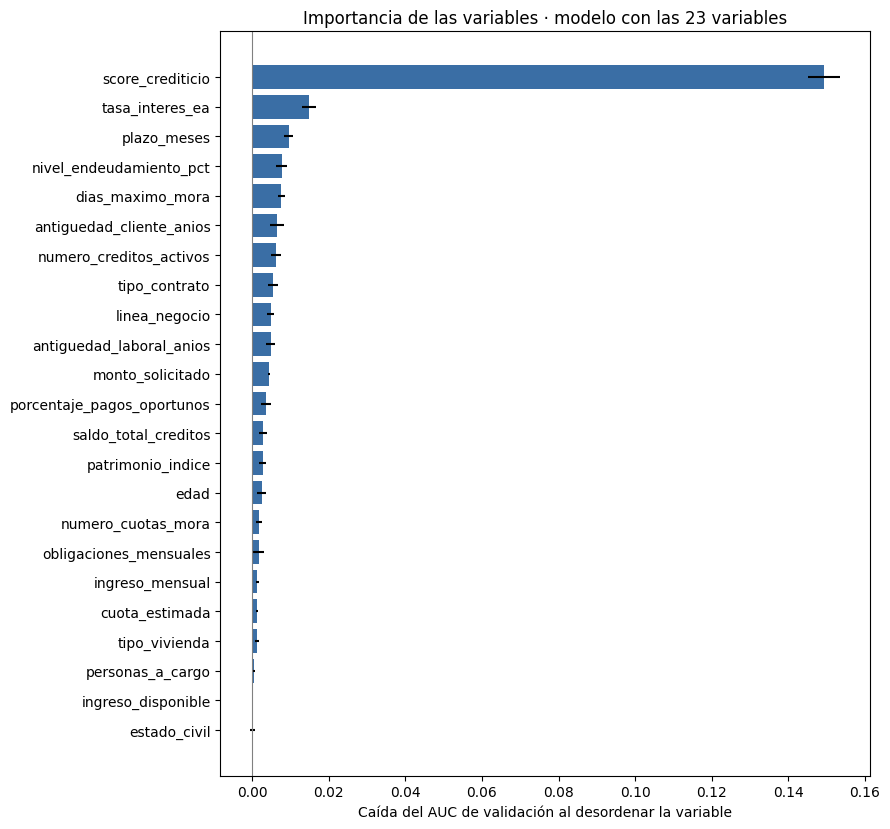

,variable,caida_auc,desv,importancia_relativa_%
0,score_crediticio,0.14936,0.00418,62.24
1,tasa_interes_ea,0.01483,0.00178,6.18
2,plazo_meses,0.00952,0.00124,3.97
3,nivel_endeudamiento_pct,0.00771,0.00140,3.21
4,dias_maximo_mora,0.00764,0.00087,3.18
5,antiguedad_cliente_anios,0.00645,0.00175,2.69
6,numero_creditos_activos,0.00616,0.00129,2.57
7,tipo_contrato,0.00535,0.00130,2.23
8,linea_negocio,0.00479,0.00084,2.00
9,antiguedad_laboral_anios,0.00477,0.00108,1.99


In [ ]:
def importancia_permutacion(modelo, prep, variables, repeticiones=5):
    rng = np.random.default_rng(SEMILLA)
    auc_base = roc_auc_score(y_val, modelo.predict(prep.transform(X_val), verbose=0).ravel())
    filas = []
    for var in variables:
        caidas = []
        for _ in range(repeticiones):
            X_perm = X_val.copy()
            X_perm[var] = rng.permutation(X_perm[var].values)
            caidas.append(auc_base - roc_auc_score(y_val, modelo.predict(prep.transform(X_perm), verbose=0).ravel()))
        filas.append({'variable': var, 'caida_auc': np.mean(caidas), 'desv': np.std(caidas)})
    imp = pd.DataFrame(filas).sort_values('caida_auc', ascending=False).reset_index(drop=True)
    imp['importancia_relativa_%'] = (100 * imp['caida_auc'].clip(lower=0) / imp['caida_auc'].clip(lower=0).sum()).round(2)
    return imp, auc_base

def graficar_importancia(imp, titulo):
    orden = imp.iloc[::-1]
    plt.figure(figsize=(9, 0.3 * len(imp) + 1.5))
    plt.barh(orden['variable'], orden['caida_auc'], xerr=orden['desv'], color='#3a6ea5')
    plt.axvline(0, color='gray', lw=0.8)
    plt.xlabel('Caída del AUC de validación al desordenar la variable')
    plt.title(titulo)
    plt.tight_layout(); plt.show()

importancia_completo, _ = importancia_permutacion(modelo_completo, prep_completo, TODAS)
importancia_completo.to_csv('importancia_variables_modelo_completo.csv', index=False)
graficar_importancia(importancia_completo, 'Importancia de las variables · modelo con las 23 variables')
importancia_completo.round(5)

In [ ]:
# Se calcula sobre el conjunto de entrenamiento, con las variables ya transformadas e imputadas (lo que ve la red)
Xf = pd.DataFrame(prep_completo.transform(X_train)[:, :len(NUMERICAS)], columns=NUMERICAS)

# Correlación de Spearman entre variables numéricas
correlacion = Xf.corr(method='spearman')

# VIF: VIF_j = 1 / (1 - R²_j), con R²_j de la regresión lineal de la variable j sobre las demás
def calcular_vif(D):
    vif = {}
    for col in D.columns:
        otras = np.column_stack([np.ones(len(D)), D.drop(columns=col).values])
        coef, *_ = np.linalg.lstsq(otras, D[col].values, rcond=None)
        r2 = 1 - ((D[col].values - otras @ coef) ** 2).sum() / ((D[col].values - D[col].mean()) ** 2).sum()
        vif[col] = 1 / max(1 - r2, 1e-12)
    return pd.Series(vif)

vif = calcular_vif(Xf)

# AUC univariado (relevancia individual): 0,5 = no separa las clases; se toma max(AUC, 1 - AUC)
def auc_univariado(serie):
    s = pd.DataFrame({'x': serie.values, 'y': y_train}).dropna()
    a = roc_auc_score(s['y'], s['x'])
    return max(a, 1 - a)

filtro = pd.DataFrame({
    'auc_univariado': [auc_univariado(X_train[c]) for c in NUMERICAS],
    'vif': vif.values,
    'corr_max': [correlacion[c].drop(c).abs().max() for c in NUMERICAS],
    'mas_correlacionada_con': [correlacion[c].drop(c).abs().idxmax() for c in NUMERICAS],
}, index=NUMERICAS).round(3)
filtro['alerta'] = np.where(filtro['vif'] > 10, 'VIF > 10', np.where(filtro['corr_max'] > 0.8, '|r| > 0,8', ''))
filtro.to_csv('seleccion_filtro.csv')
filtro.sort_values('vif', ascending=False)

,auc_univariado,vif,corr_max,mas_correlacionada_con,alerta
monto_solicitado,0.523,76.808,0.823,cuota_estimada,VIF > 10
cuota_estimada,0.503,49.656,0.823,monto_solicitado,VIF > 10
plazo_meses,0.527,17.392,0.681,tasa_interes_ea,VIF > 10
nivel_endeudamiento_pct,0.519,3.627,0.692,obligaciones_mensuales,
numero_cuotas_mora,0.549,3.343,0.875,porcentaje_pagos_oportunos,"|r| > 0,8"
tasa_interes_ea,0.577,2.665,0.681,plazo_meses,
porcentaje_pagos_oportunos,0.562,2.479,0.875,numero_cuotas_mora,"|r| > 0,8"
ingreso_mensual,0.519,2.415,0.824,ingreso_disponible,"|r| > 0,8"
dias_maximo_mora,0.554,2.258,0.843,porcentaje_pagos_oportunos,"|r| > 0,8"
obligaciones_mensuales,0.503,2.072,0.692,nivel_endeudamiento_pct,


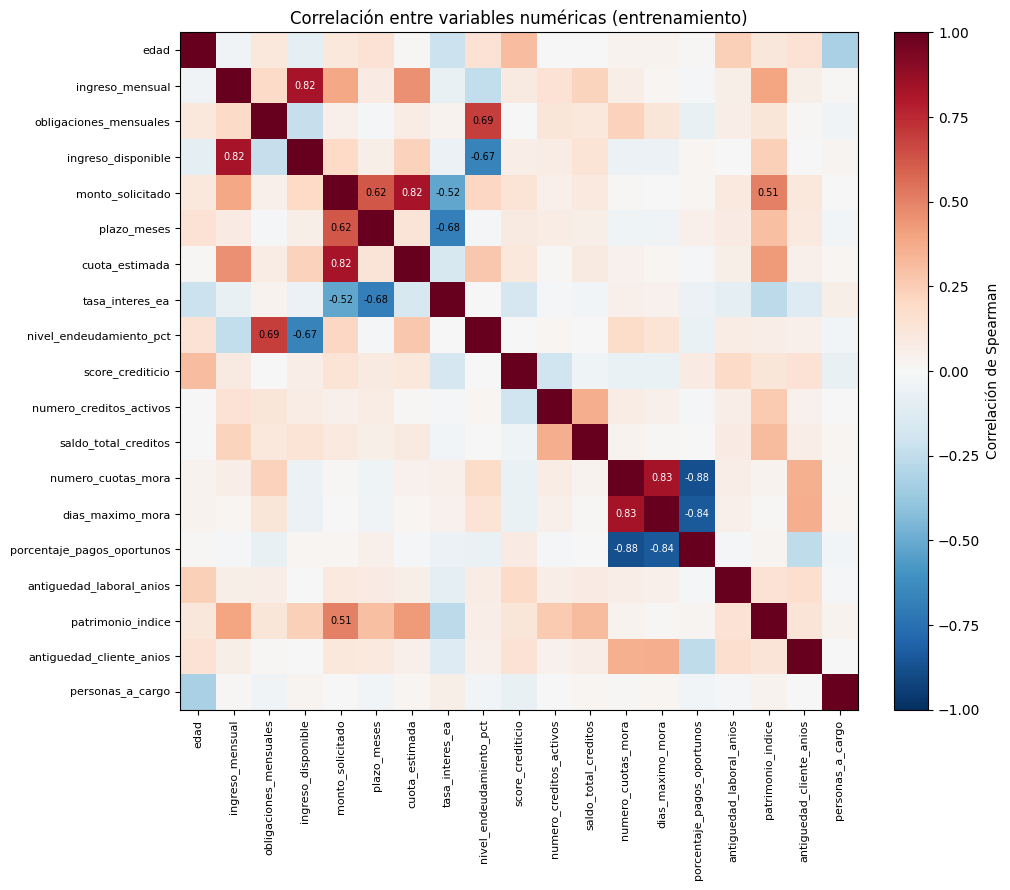

,V de Cramér con el objetivo
estado_civil,0.0759
linea_negocio,0.0593
tipo_contrato,0.1342
tipo_vivienda,0.0655


In [ ]:
# Mapa de correlaciones (solo se anotan las |r| >= 0,5)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(correlacion.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERICAS))); ax.set_xticklabels(NUMERICAS, rotation=90, fontsize=8)
ax.set_yticks(range(len(NUMERICAS))); ax.set_yticklabels(NUMERICAS, fontsize=8)
for i in range(len(NUMERICAS)):
    for j in range(len(NUMERICAS)):
        r = correlacion.values[i, j]
        if i != j and abs(r) >= 0.5:
            ax.text(j, i, f'{r:.2f}', ha='center', va='center', fontsize=7, color='white' if abs(r) > 0.75 else 'black')
plt.colorbar(im, fraction=0.046, pad=0.04, label='Correlación de Spearman')
ax.set_title('Correlación entre variables numéricas (entrenamiento)')
plt.tight_layout(); plt.show()

# Asociación de las categóricas con el objetivo: V de Cramér
def v_cramer(serie):
    tabla = pd.crosstab(serie, y_train).values
    n = tabla.sum(); esperado = tabla.sum(1, keepdims=True) * tabla.sum(0, keepdims=True) / n
    chi2 = ((tabla - esperado) ** 2 / esperado).sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

pd.Series({v: v_cramer(X_train[v]) for v in CATEGORIAS}, name='V de Cramér con el objetivo').round(4).to_frame()

In [ ]:
EJECUTAR_SELECCION = True
K_ELIMINAR = [0, 4, 8, 12, 16]

# Conjunto elegido en la corrida de referencia; se usa si EJECUTAR_SELECCION = False
VARIABLES_FINALES = ['score_crediticio', 'tasa_interes_ea', 'plazo_meses', 'antiguedad_laboral_anios', 'antiguedad_cliente_anios', 'nivel_endeudamiento_pct', 'numero_creditos_activos', 'linea_negocio', 'dias_maximo_mora', 'patrimonio_indice', 'porcentaje_pagos_oportunos', 'tipo_contrato', 'saldo_total_creditos', 'edad', 'cuota_estimada']

if EJECUTAR_SELECCION:
    ranking = list(importancia_completo['variable'])          # de mayor a menor importancia
    filas = []
    for k in K_ELIMINAR:
        conservadas = ranking[:len(ranking) - k]
        for s in SEMILLAS_POOL:
            r = correr_configuracion(CONFIG_ELEGIDA['imputacion'], CONFIG_ELEGIDA['indicadores'],
                                     CONFIG_ELEGIDA['transformacion'], CONFIG_ELEGIDA['dropout'],
                                     CONFIG_ELEGIDA['tam_lote'], CONFIG_ELEGIDA['activacion'],
                                     variables=conservadas, semilla=s)
            r.update(k_eliminadas=k, eliminadas=', '.join(ranking[len(ranking) - k:]))
            filas.append(r)
        print(f'k={k:2d} | {len(conservadas)} variables | AUC val = {promedio_ultimas(filas):.4f}')
    seleccion = pd.DataFrame(filas)
    seleccion.to_csv('seleccion_eliminacion.csv', index=False)

    resumen_sel = (seleccion.groupby('k_eliminadas')
                   .agg(n_variables=('n_variables', 'first'), entradas=('entradas', 'first'),
                        auc_val=('auc_val', 'mean'), desv_auc=('auc_val', 'std'))
                   .round(4))
    display(resumen_sel)

k= 0 | 23 variables | AUC val = 0.7456
k= 4 | 19 variables | AUC val = 0.7455
k= 8 | 15 variables | AUC val = 0.7453
k=12 | 11 variables | AUC val = 0.7431
k=16 | 7 variables | AUC val = 0.7341


,n_variables,entradas,auc_val,desv_auc
k_eliminadas,,,,
0,23,43,0.7456,0.0010
4,19,32,0.7455,0.0011
8,15,26,0.7453,0.0006
12,11,20,0.7431,0.0008
16,7,9,0.7341,0.0005


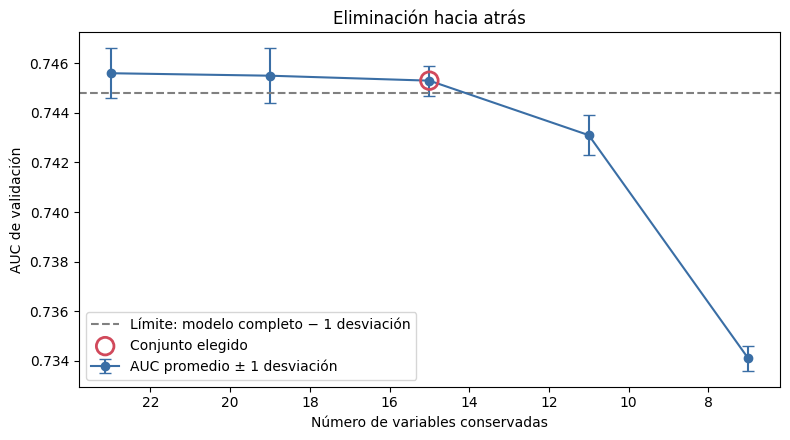

Ruido entre semillas: 0.0008 | Límite de AUC: 0.7448 | Se eliminan 8 variables
Variables conservadas (15): ['score_crediticio', 'tasa_interes_ea', 'plazo_meses', 'nivel_endeudamiento_pct', 'dias_maximo_mora', 'antiguedad_cliente_anios', 'numero_creditos_activos', 'tipo_contrato', 'linea_negocio', 'antiguedad_laboral_anios', 'monto_solicitado', 'porcentaje_pagos_oportunos', 'saldo_total_creditos', 'patrimonio_indice', 'edad']
Variables eliminadas (8): ['ingreso_mensual', 'obligaciones_mensuales', 'ingreso_disponible', 'cuota_estimada', 'numero_cuotas_mora', 'personas_a_cargo', 'estado_civil', 'tipo_vivienda']


In [ ]:
if EJECUTAR_SELECCION:
    ruido = resumen_sel['desv_auc'].mean()               # variación típica entre semillas
    limite = resumen_sel.loc[0, 'auc_val'] - ruido
    aceptables = resumen_sel[resumen_sel['auc_val'] >= limite]
    k_elegido = int(aceptables.index.max())
    VARIABLES_FINALES = ranking[:len(ranking) - k_elegido]

    plt.figure(figsize=(8, 4.5))
    plt.errorbar(resumen_sel['n_variables'], resumen_sel['auc_val'], yerr=resumen_sel['desv_auc'],
                 marker='o', capsize=4, color='#3a6ea5', label='AUC promedio ± 1 desviación')
    plt.axhline(limite, ls='--', color='gray', label='Límite: modelo completo − 1 desviación')
    plt.scatter([len(VARIABLES_FINALES)], [resumen_sel.loc[k_elegido, 'auc_val']], s=160,
                facecolors='none', edgecolors='#d1495b', linewidths=2, label='Conjunto elegido', zorder=3)
    plt.gca().invert_xaxis()
    plt.xlabel('Número de variables conservadas'); plt.ylabel('AUC de validación')
    plt.title('Eliminación hacia atrás')
    plt.legend(); plt.tight_layout(); plt.show()

    print(f'Ruido entre semillas: {ruido:.4f} | Límite de AUC: {limite:.4f} | Se eliminan {k_elegido} variables')

eliminadas = [v for v in TODAS if v not in VARIABLES_FINALES]
print(f'Variables conservadas ({len(VARIABLES_FINALES)}):', VARIABLES_FINALES)
print(f'Variables eliminadas ({len(eliminadas)}):', eliminadas)

In [ ]:
modelo, prep, historia = entrenar_modelo(VARIABLES_FINALES, verbose=2)
modelo.summary()
Xva, Xte = prep.transform(X_val), prep.transform(X_test)
print('Neuronas de entrada:', Xva.shape[1], '| Épocas entrenadas:', len(historia.history['loss']))

Epoch 1/200
1087/1087 - 6s - 5ms/step - accuracy: 0.6483 - auc: 0.7006 - loss: 0.6344 - val_accuracy: 0.6767 - val_auc: 0.7388 - val_loss: 0.6044 - learning_rate: 0.0010
Epoch 2/200
1087/1087 - 3s - 3ms/step - accuracy: 0.6754 - auc: 0.7327 - loss: 0.6093 - val_accuracy: 0.6814 - val_auc: 0.7420 - val_loss: 0.6008 - learning_rate: 0.0010
Epoch 3/200
1087/1087 - 3s - 3ms/step - accuracy: 0.6815 - auc: 0.7405 - loss: 0.6031 - val_accuracy: 0.6814 - val_auc: 0.7438 - val_loss: 0.5985 - learning_rate: 0.0010
Epoch 4/200
1087/1087 - 3s - 3ms/step - accuracy: 0.6841 - auc: 0.7435 - loss: 0.5998 - val_accuracy: 0.6775 - val_auc: 0.7437 - val_loss: 0.5971 - learning_rate: 0.0010
Epoch 5/200
1087/1087 - 4s - 3ms/step - accuracy: 0.6859 - auc: 0.7458 - loss: 0.5978 - val_accuracy: 0.6814 - val_auc: 0.7434 - val_loss: 0.5981 - learning_rate: 0.0010
Epoch 6/200
1087/1087 - 4s - 4ms/step - accuracy: 0.6832 - auc: 0.7461 - loss: 0.5978 - val_accuracy: 0.6763 - val_auc: 0.7441 - val_loss: 0.5980 - le

Model: "sequential_71"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 64)             │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_213 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_214 (Dropout)           │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_3 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_215 (Dropout)           │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,061 (51.02 KB)

 Trainable params: 4,353 (17.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,708 (34.02 KB)

Neuronas de entrada: 26 | Épocas entrenadas: 30


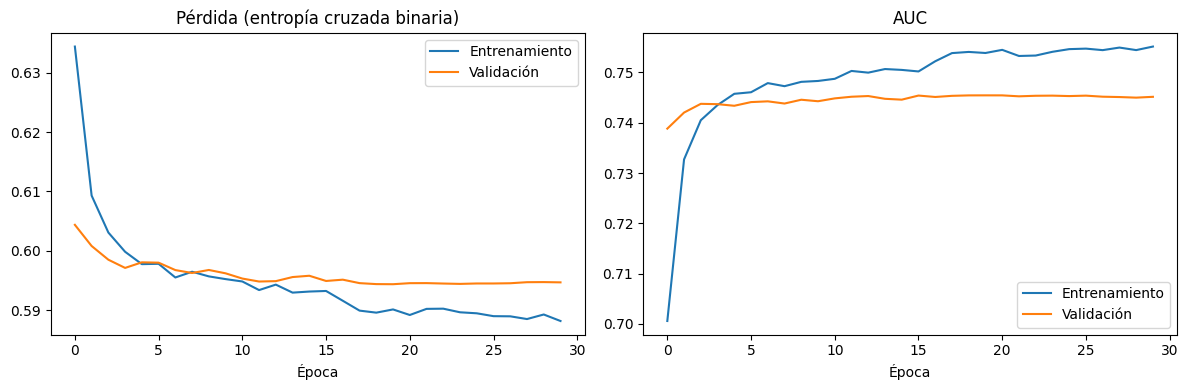

In [ ]:
h = historia.history
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(h['loss'], label='Entrenamiento'); ejes[0].plot(h['val_loss'], label='Validación')
ejes[0].set_title('Pérdida (entropía cruzada binaria)'); ejes[0].set_xlabel('Época'); ejes[0].legend()
ejes[1].plot(h['auc'], label='Entrenamiento'); ejes[1].plot(h['val_auc'], label='Validación')
ejes[1].set_title('AUC'); ejes[1].set_xlabel('Época'); ejes[1].legend()
plt.tight_layout(); plt.show()

AUC de validación del modelo final: 0.7455 (modelo completo: 0.7459)


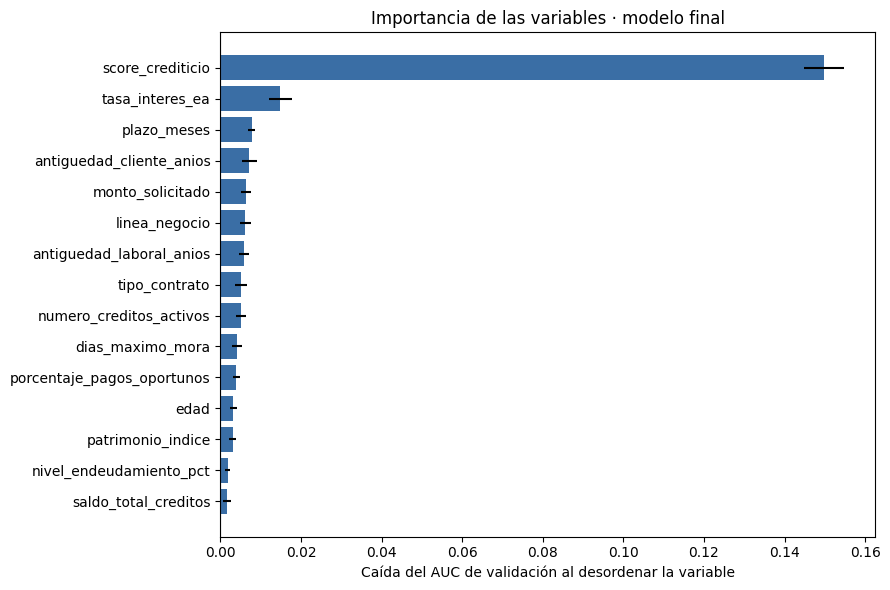

,variable,caida_auc,desv,importancia_relativa_%
0,score_crediticio,0.14980,0.00487,66.26
1,tasa_interes_ea,0.01482,0.00284,6.55
2,plazo_meses,0.00780,0.00091,3.45
3,antiguedad_cliente_anios,0.00718,0.00184,3.18
4,monto_solicitado,0.00631,0.00125,2.79
5,linea_negocio,0.00621,0.00137,2.75
6,antiguedad_laboral_anios,0.00585,0.00124,2.59
7,tipo_contrato,0.00515,0.00146,2.28
8,numero_creditos_activos,0.00514,0.00115,2.27
9,dias_maximo_mora,0.00415,0.00124,1.84


In [ ]:
importancia, auc_val_final = importancia_permutacion(modelo, prep, VARIABLES_FINALES)
importancia.to_csv('importancia_variables.csv', index=False)
print(f'AUC de validación del modelo final: {auc_val_final:.4f} (modelo completo: {auc_completo:.4f})')
graficar_importancia(importancia, 'Importancia de las variables · modelo final')
importancia.round(5)

In [ ]:
PREV_INCUMPLIMIENTO = 24825 / 307511          # prevalencia real en application_train (8,07 %)
UMBRAL = 0.5

p_test = modelo.predict(Xte, verbose=0).ravel()
pred_test = (p_test >= UMBRAL).astype(int)
pesos_reales = np.where(y_test == 1, (1 - PREV_INCUMPLIMIENTO) / 0.5, PREV_INCUMPLIMIENTO / 0.5)

def metricas(y, p, pred, w=None):
    return {
        'AUC-ROC': roc_auc_score(y, p, sample_weight=w),
        'Exactitud': accuracy_score(y, pred, sample_weight=w),
        'Precisión (apto)': precision_score(y, pred, sample_weight=w),
        'Sensibilidad (apto)': recall_score(y, pred, sample_weight=w),
        'F1 (apto)': f1_score(y, pred, sample_weight=w),
        'Precisión (no apto)': precision_score(y, pred, pos_label=0, sample_weight=w),
        'Sensibilidad (no apto)': recall_score(y, pred, pos_label=0, sample_weight=w),
        'F1 (no apto)': f1_score(y, pred, pos_label=0, sample_weight=w),
        'AUC-PR (no apto)': average_precision_score(1 - y, 1 - p, sample_weight=w),
    }

tabla_metricas = pd.DataFrame({
    'Prueba balanceada (50/50)': metricas(y_test, p_test, pred_test),
    'Prevalencia real (8,07 %)': metricas(y_test, p_test, pred_test, pesos_reales),
}).round(4)
tabla_metricas.to_csv('metricas_prueba.csv')
tabla_metricas

,Prueba balanceada (50/50),"Prevalencia real (8,07 %)"
AUC-ROC,0.7459,0.7459
Exactitud,0.6820,0.6815
Precisión (apto),0.6822,0.9607
Sensibilidad (apto),0.6814,0.6814
F1 (apto),0.6818,0.7973
Precisión (no apto),0.6818,0.1583
Sensibilidad (no apto),0.6826,0.6826
F1 (no apto),0.6822,0.2570
AUC-PR (no apto),0.7344,0.2238


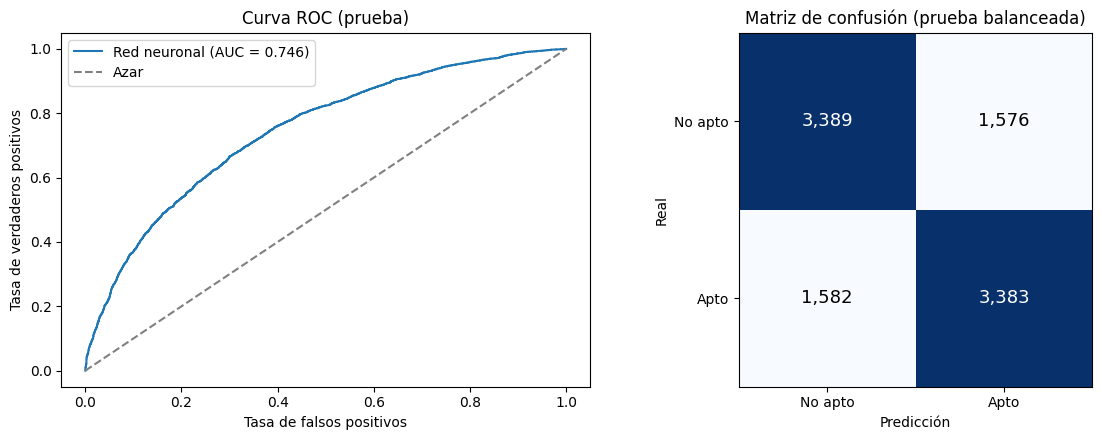

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

fpr, tpr, _ = roc_curve(y_test, p_test)
ejes[0].plot(fpr, tpr, label=f'Red neuronal (AUC = {roc_auc_score(y_test, p_test):.3f})')
ejes[0].plot([0, 1], [0, 1], '--', color='gray', label='Azar')
ejes[0].set_xlabel('Tasa de falsos positivos'); ejes[0].set_ylabel('Tasa de verdaderos positivos')
ejes[0].set_title('Curva ROC (prueba)'); ejes[0].legend()

cm = confusion_matrix(y_test, pred_test, labels=[0, 1])
ejes[1].imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ejes[1].text(j, i, f'{cm[i, j]:,}', ha='center', va='center',
                     color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=13)
ejes[1].set_xticks([0, 1]); ejes[1].set_xticklabels(['No apto', 'Apto'])
ejes[1].set_yticks([0, 1]); ejes[1].set_yticklabels(['No apto', 'Apto'])
ejes[1].set_xlabel('Predicción'); ejes[1].set_ylabel('Real'); ejes[1].set_title('Matriz de confusión (prueba balanceada)')
plt.tight_layout(); plt.show()

Probabilidad corregida a la población real
La sigmoide entrega la probabilidad de ser apto **en una población 50/50**. Para leerla en la población real se aplica la corrección de priors:

$$p_{real} = \frac{p \cdot a}{p \cdot a + (1-p) \cdot b}, \quad a = \frac{0{,}9193}{0{,}5}, \; b = \frac{0{,}0807}{0{,}5}$$

La corrección no cambia el orden de los solicitantes (el AUC es el mismo), solo la escala de la probabilidad.

In [ ]:
def probabilidad_real(p):
    a, b = (1 - PREV_INCUMPLIMIENTO) / 0.5, PREV_INCUMPLIMIENTO / 0.5
    return p * a / (p * a + (1 - p) * b)

ejemplos = np.array([0.2, 0.35, 0.5, 0.65, 0.8])
pd.DataFrame({'Salida de la red (50/50)': ejemplos, 'Probabilidad real de ser apto': probabilidad_real(ejemplos)}).round(3)

,Salida de la red (50/50),Probabilidad real de ser apto
0,0.20,0.740
1,0.35,0.860
2,0.50,0.919
3,0.65,0.955
4,0.80,0.979


In [ ]:
modelo.save('modelo_credito_mlp.keras')

config_export = prep.a_diccionario()
config_export.update(
    variables=VARIABLES_FINALES, umbral=UMBRAL, prevalencia_incumplimiento=PREV_INCUMPLIMIENTO,
    configuracion=CONFIG_ELEGIDA, keras_version=keras.__version__ if hasattr(keras, '__version__') else tf.__version__,
    fecha=time.strftime('%Y-%m-%d'))
with open('preprocesador.json', 'w', encoding='utf-8') as f:
    json.dump(config_export, f, ensure_ascii=False, indent=2)
print('preprocesador.json:', len(config_export['nombres_entradas']), 'entradas de la red')

preprocesador.json: 26 entradas de la red


In [ ]:
CODIGO_PREDECIR = r"""
# predecir.py - Prediccion con la red neuronal de credito, fuera de Colab.
#
# Uso:   python predecir.py solicitantes.csv [resultados.csv]
# Requiere en la misma carpeta: modelo_credito_mlp.keras y preprocesador.json
# Instalar: pip install tensorflow pandas numpy
import json, os, sys
import numpy as np
import pandas as pd

CARPETA = os.path.dirname(os.path.abspath(__file__))


def cargar(carpeta=CARPETA):
    from tensorflow import keras
    with open(os.path.join(carpeta, 'preprocesador.json'), encoding='utf-8') as f:
        cfg = json.load(f)
    modelo = keras.models.load_model(os.path.join(carpeta, 'modelo_credito_mlp.keras'))
    return modelo, cfg


def transformar(df, cfg):
    # Aplica exactamente el mismo preprocesamiento del notebook con los valores aprendidos en el entrenamiento
    faltan = [c for c in cfg['variables'] if c not in df.columns]
    if faltan:
        raise ValueError(f'Faltan columnas en el archivo de entrada: {faltan}')
    num = cfg['numericas']
    Xn = df[num].astype(float).copy()
    indic = Xn[cfg['cols_indicador']].isna().astype(float).values
    if cfg['transformacion'] == 'log':
        cols = cfg['cola_larga']
        Xn[cols] = np.sign(Xn[cols]) * np.log1p(Xn[cols].abs())
    elif cfg['transformacion'] == 'recorte':
        Xn = Xn.clip(pd.Series(cfg['p01'])[num], pd.Series(cfg['p99'])[num], axis=1)
    Xn = Xn.fillna(pd.Series(cfg['relleno'])[num])
    Xn = ((Xn - pd.Series(cfg['media'])[num]) / pd.Series(cfg['desv'])[num]).values
    partes = [Xn, indic]
    if cfg['categorias']:
        partes.append(np.column_stack([(df[v].values == c).astype(float)
                                       for v, cats in cfg['categorias'].items() for c in cats[1:]]))
    X = np.hstack(partes).astype('float32')
    assert X.shape[1] == len(cfg['nombres_entradas'])
    return X


def probabilidad_real(p, prevalencia):
    a, b = (1 - prevalencia) / 0.5, prevalencia / 0.5
    return p * a / (p * a + (1 - p) * b)


def predecir(df, modelo=None, cfg=None):
    if modelo is None or cfg is None:
        modelo, cfg = cargar()
    p = modelo.predict(transformar(df, cfg), verbose=0).ravel()
    return pd.DataFrame({
        'prob_apto_50_50': p,
        'prob_apto_real': probabilidad_real(p, cfg['prevalencia_incumplimiento']),
        'decision': np.where(p >= cfg['umbral'], 'APTO', 'NO APTO'),
    }, index=df.index)


if __name__ == '__main__':
    if len(sys.argv) < 2:
        print(__doc__ or 'Uso: python predecir.py solicitantes.csv [resultados.csv]')
        sys.exit(1)
    entrada = pd.read_csv(sys.argv[1], encoding='utf-8-sig')
    resultado = pd.concat([entrada, predecir(entrada)], axis=1)
    salida = sys.argv[2] if len(sys.argv) > 2 else 'resultados_prediccion.csv'
    resultado.to_csv(salida, index=False, encoding='utf-8-sig')
    print(f'{len(resultado)} solicitantes evaluados -> {salida}')
    print(resultado['decision'].value_counts().to_string())
"""
with open('predecir.py', 'w', encoding='utf-8') as f:
    f.write(CODIGO_PREDECIR.lstrip())
print('predecir.py creado')

predecir.py creado


In [ ]:
import importlib, sys
sys.path.insert(0, os.getcwd())
import predecir as script_prediccion
importlib.reload(script_prediccion)

modelo_cargado, cfg_cargado = script_prediccion.cargar('.')
res = script_prediccion.predecir(X_test, modelo_cargado, cfg_cargado)
diferencia = np.abs(res['prob_apto_50_50'].values - p_test).max()
print(f'Diferencia máxima con el notebook: {diferencia:.2e}')
assert diferencia < 1e-5, 'La exportación no reproduce las predicciones del notebook'
print('Exportación verificada: el script reproduce exactamente las predicciones.')

# 5 solicitantes de prueba que cubren de la probabilidad más baja a la más alta
idx = np.argsort(p_test)[np.linspace(0, len(p_test) - 1, 5).astype(int)]
ejemplo = X_test[[c for c in X.columns if c in VARIABLES_FINALES]].iloc[idx]
ejemplo.to_csv('solicitantes_ejemplo.csv', index=False, encoding='utf-8-sig')
print('Creado solicitantes_ejemplo.csv. Prueba fuera de Colab: python predecir.py solicitantes_ejemplo.csv')
res.iloc[idx]

Diferencia máxima con el notebook: 0.00e+00
Exportación verificada: el script reproduce exactamente las predicciones.
Creado solicitantes_ejemplo.csv. Prueba fuera de Colab: python predecir.py solicitantes_ejemplo.csv


,prob_apto_50_50,prob_apto_real,decision
8289,0.030843,0.265998,NO APTO
267,0.327645,0.847307,NO APTO
12423,0.499400,0.919093,NO APTO
20973,0.670326,0.958598,APTO
2043,0.954744,0.995855,APTO


In [ ]:
# Guardado de las tablas de resultados
filtro.to_csv('seleccion_filtro.csv')
archivos = ['modelo_credito_mlp.keras', 'preprocesador.json', 'predecir.py', 'solicitantes_ejemplo.csv',
            'metricas_prueba.csv', 'importancia_variables.csv', 'importancia_variables_modelo_completo.csv',
            'seleccion_filtro.csv']
archivos += [a for a in ['pool1_preprocesamiento.csv', 'pool2_hiperparametros.csv', 'pool3_activacion.csv',
                         'seleccion_eliminacion.csv'] if os.path.exists(a)]
print('Archivos generados:'); print('\n'.join('  ' + a for a in archivos))

# En Colab, para descargarlos todos en un .zip:
#   import shutil; from google.colab import files
#   os.makedirs('resultados', exist_ok=True); [shutil.copy(a, 'resultados') for a in archivos]
#   shutil.make_archive('resultados', 'zip', 'resultados'); files.download('resultados.zip')

Archivos generados:
  modelo_credito_mlp.keras
  preprocesador.json
  predecir.py
  solicitantes_ejemplo.csv
  metricas_prueba.csv
  importancia_variables.csv
  importancia_variables_modelo_completo.csv
  seleccion_filtro.csv
  pool1_preprocesamiento.csv
  pool2_hiperparametros.csv
  pool3_activacion.csv
  seleccion_eliminacion.csv
